In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [2]:
df = pd.read_csv("../data/institution_type_large.csv")

X = df.drop("Toplam Harcama", axis=1)
y = df["Toplam Harcama"]

In [3]:
df = df.rename(columns={
    "Yil": "year",
    "Ay": "month",
    "Kurum Turu": "institution_type",
    "Muracaat Sayisi": "application_count",
    "Kronik Hasta Orani": "chronic_ratio",
    "Saglik Enflasyonu": "health_inflation",
    "Kisi Basi Maliyet": "unit_cost",
    "Toplam Harcama": "total_amount"
})

In [4]:
features = [
    "year",
    "month",
    "institution_type",
    "application_count",
    "chronic_ratio",
    "health_inflation",
    "unit_cost"
]

target = "total_amount"

df = df[features + [target]].dropna()

X = df[features]
y = df[target]

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
#Preprocessing
categorical_features = ["institution_type"]
numeric_features = [col for col in X.columns if col not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first"), categorical_features),
        ("num", StandardScaler(), numeric_features)
    ]
)

In [7]:
#Models
models = {
    "Ridge Regression": Ridge(alpha=1.0, random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        max_features='sqrt',
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=5,
        random_state=42
    )
}

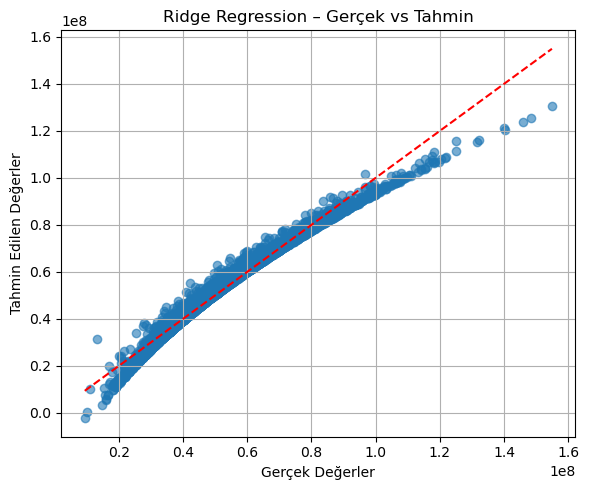

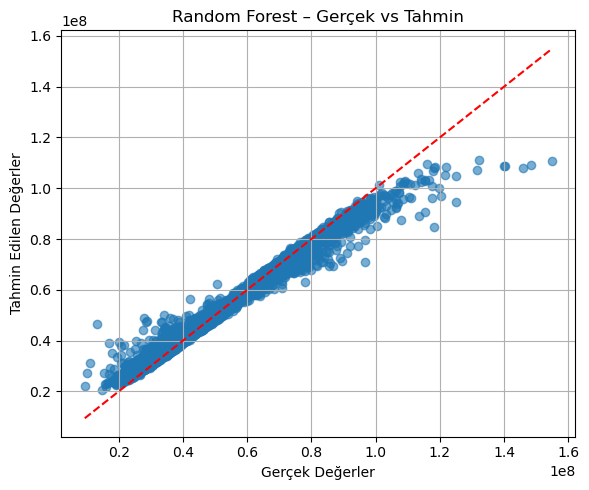

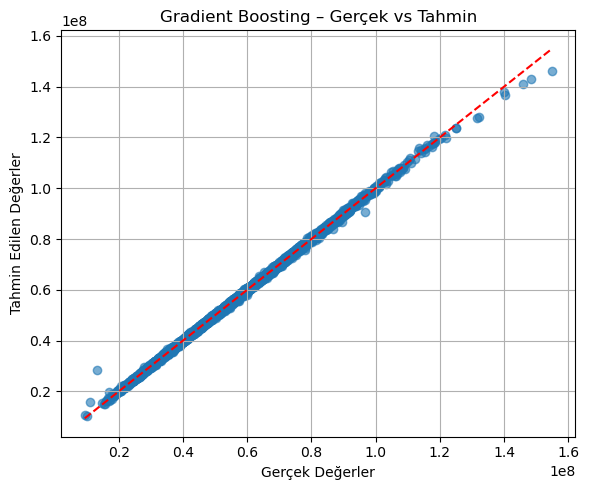

               Model  R2 Score          RMSE           MAE
0   Ridge Regression  0.981354  2.419664e+06  1.574924e+06
1      Random Forest  0.967459  3.196558e+06  1.822688e+06
2  Gradient Boosting  0.999315  4.636965e+05  2.906626e+05


In [8]:
#Train & Evaluate
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

results = []

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred)
    })
    
    # 🎯 Her model için scatter plot burada
    plt.figure(figsize=(6, 5))
    plt.scatter(y_test, y_pred, alpha=0.6)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r')
    plt.xlabel("Gerçek Değerler")
    plt.ylabel("Tahmin Edilen Değerler")
    plt.title(f"{name} – Gerçek vs Tahmin")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Tüm modellerin sonuç tablosu
results_df = pd.DataFrame(results)
print(results_df)

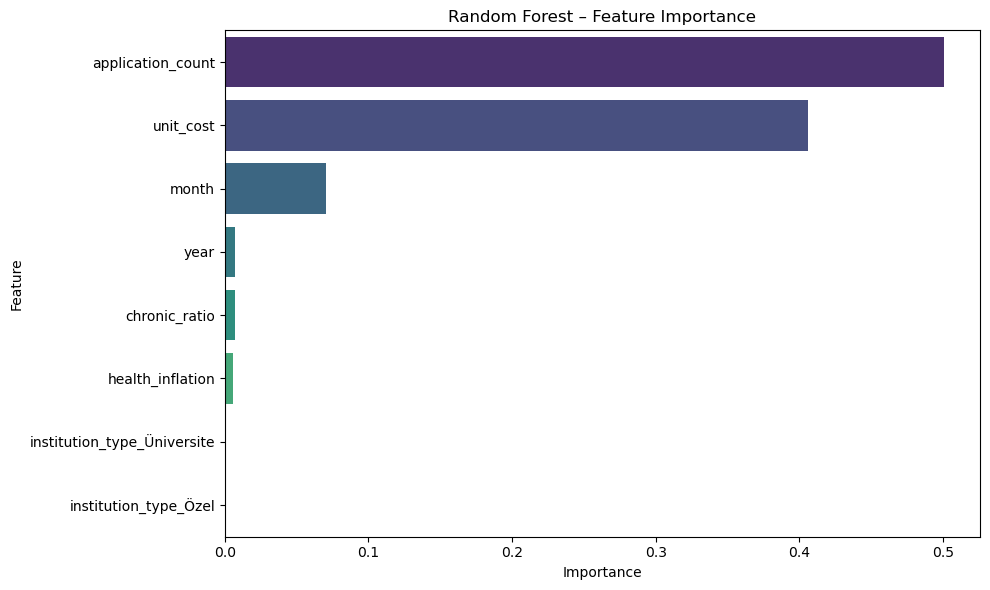

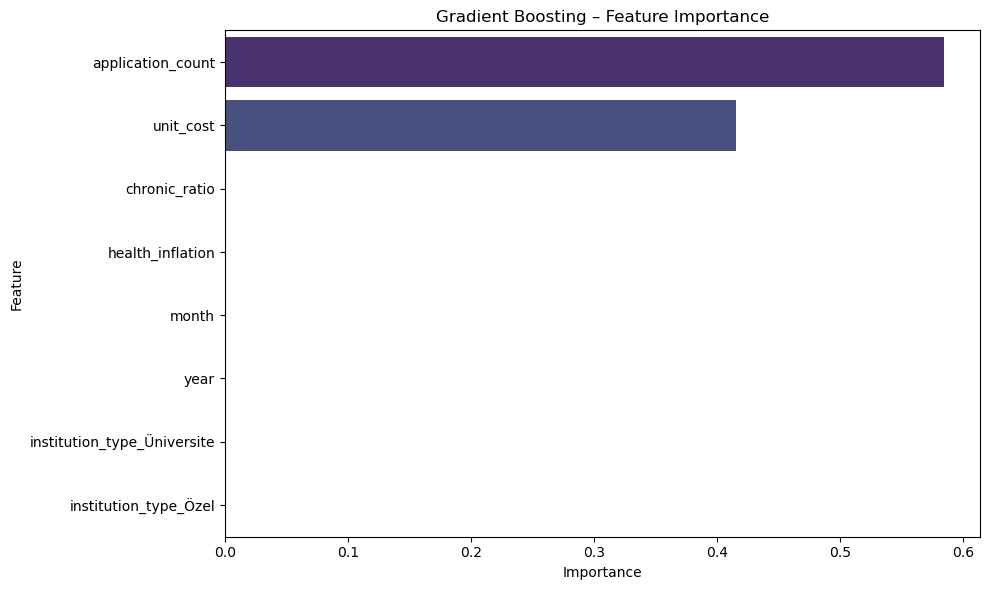

In [24]:
#Feature Importance (Random Forest & Gradient Boosting)
for name, model in models.items():
    if name in ["Random Forest", "Gradient Boosting"]:
        pipeline = Pipeline(steps=[
            ('preprocessor', preprocessor),
            ('regressor', model)
        ])
        pipeline.fit(X_train, y_train)
        
        # Get feature names after preprocessing
        ohe = pipeline.named_steps['preprocessor'].named_transformers_['cat']
        encoded_features = list(ohe.get_feature_names_out(categorical_features))
        all_features = encoded_features + numeric_features
        
        # Feature importance
        importances = pipeline.named_steps['regressor'].feature_importances_
        importance_df = pd.DataFrame({
            'Feature': all_features,
            'Importance': importances
        }).sort_values(by='Importance', ascending=False)
        
        plt.figure(figsize=(10, 6))
        plt.title(f'{name} – Feature Importance')
        sns.barplot(
        x='Importance',
        y='Feature',
        data=importance_df,
        hue='Feature',
        dodge=False,
        legend=False,
        palette="viridis"
        )
        plt.tight_layout()
        plt.show()

In [11]:
import os

os.makedirs("../models", exist_ok=True)

In [14]:
#save models
from joblib import dump

# Ridge Regression
ridge_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1.0, random_state=42))
])
ridge_pipeline.fit(X_train, y_train)
dump(ridge_pipeline, "../models/institution_ridge.pkl")

# Random Forest
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=5,
        max_features='sqrt',
        random_state=42
    ))
])
rf_pipeline.fit(X_train, y_train)
dump(rf_pipeline, "../models/institution_rf.pkl")

# Gradient Boosting
gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=5,
        random_state=42
    ))
])
gb_pipeline.fit(X_train, y_train)
dump(gb_pipeline, "../models/institution_gb.pkl")

['../models/institution_gb.pkl']